# AI-Driven Energy Supply Chain Resilience — Demo

**A dual-agent (Hawk/Dove) geopolitical risk agent for India's crude oil supply chain.**

This notebook is the single narrated walkthrough of the real, already-built pipeline — it loads
and displays actual outputs from your runs (Steps 1-5/7), it does not recompute the full
13-month pipeline live (that takes hours and real API/LLM spend). The one thing it *does* call
live is a cheap, free retrieval-layer safety check (Section 6) — everything else here is
reading and presenting artifacts your other notebooks already produced.

**Run every cell top to bottom before presenting.** Each section checks whether its input file
exists and prints a clear "run notebook X first" message instead of crashing if something is
missing — so a partial pipeline still demos the parts that are ready, rather than failing
outright mid-presentation.

**What this demo covers, mapped to the judging criteria:**
- **Innovation** — Section 5: the adversarial Hawk/Dove/Adjudicator debate, a real disagreement
  between two independent LLM analysts reasoned over cited evidence, not a single black-box score.
- **Technical Excellence** — Section 1 (noise reduction with a documented, auditable pipeline),
  Section 6 (a live-executed guardrail test, not a claimed one).
- **Business Impact** — Section 8: the final ranked Disruption Alerts, the artifact a
  procurement or policy team would actually read.
- **Scalability** — Section 7: Tier 1 runs continuously and cheaply; Tier 2 (the expensive
  LLM debate) only fires on the corridor-timestamps that are actually ambiguous.
- **User Experience** — every section below prints evidence-cited, human-readable output, not
  raw JSON dumps.

In [15]:
print("hi")

hi


## 0. Config — paths to your real pipeline outputs

In [16]:
import json
from pathlib import Path
from datetime import timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
import pickle

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

OUTPUT_DIR = Path("outputs")

STEP1_CORPUS_JSON = Path(r"D:\python time\ET\code\risk_agent\csv_backfill\gdelt\outputs\gdelt_relevant_corpus.json")
TIER1_COMPOSITE_PATH = Path(r"D:\python time\ET\code\risk_agent\code\outputs\tier1_composite.csv")
RAG_CHUNKS_PATH = OUTPUT_DIR / "rag_chunks_metadata.csv"
RAG_MATRIX_PATH = OUTPUT_DIR / "rag_tfidf_matrix.npz"
RAG_VECTORIZER_PATH = OUTPUT_DIR / "rag_tfidf_vectorizer.pkl"
STEP4_EPISODES_PATH = OUTPUT_DIR / "step4_trigger_episodes.csv"
STEP4_FINAL_RESULTS_PATH = OUTPUT_DIR / "step4_final_risk_scores.json"
STEP4_ROUND1_PATH = OUTPUT_DIR / "step4_round1_hawk_dove.json"
CALIBRATED_CONFIG_PATH = OUTPUT_DIR / "step5_final_calibrated_config.json"
UNIFIED_FEED_PATH = OUTPUT_DIR / "unified_risk_feed.csv"
DISRUPTION_ALERTS_PATH = OUTPUT_DIR / "disruption_alerts.csv"

# Known from the real Step 1 run (13-month backfill) -- recomputing this live would mean
# re-reading all 13 raw GDELT files, which is unnecessary for a demo. If you re-run Step 1,
# update this from that notebook's own printed funnel table.
STEP1_RAW_ROW_COUNT = 4_863_286
STEP1_UNIQUE_STORY_COUNT = 1_520_843

DEMO_CORRIDOR = "hormuz"   # which corridor's time series/example to feature below

def check_exists(path, step_name):
    if not Path(path).exists():
        print(f"[MISSING] {path} -- run {step_name} first. Skipping this section's live content.")
        return False
    return True


## 1. Simulated live ingestion

**What this is, honestly:** a paced replay of signals your Step 1/Tier 1 pipeline already
processed — not a live internet connection. Re-fetching and re-filtering from scratch during a
demo would be slow and depends on network access you may not have on stage. This shows the
*same filtering decisions* your pipeline actually made, presented as a live-feeling stream, so a
judge watching sees the Stage A/B logic making real keep/drop calls in real time instead of
staring at a static "here's a CSV we made earlier" table.

In [17]:
import time
import random

ENABLE_SIMULATED_INGESTION = True
SIMULATED_INGESTION_SAMPLE_SIZE = 14
SIMULATED_INGESTION_DELAY_SECONDS = 0.35   # pure pacing for demo effect, not a real fetch delay

if ENABLE_SIMULATED_INGESTION and check_exists(STEP1_CORPUS_JSON, "the Step 1 preprocessing notebook"):
    with open(STEP1_CORPUS_JSON) as f:
        _corpus_for_stream = json.load(f)

    rng = random.Random(7)
    sample = rng.sample(_corpus_for_stream, min(SIMULATED_INGESTION_SAMPLE_SIZE, len(_corpus_for_stream)))
    sample.sort(key=lambda s: s["first_seen_as_of"])

    print("Streaming replay of processed signals (source: Step 1 relevant corpus)\n")
    for story in sample:
        time.sleep(SIMULATED_INGESTION_DELAY_SECONDS)
        hits = ", ".join(story["keyword_hits"][:4]) or "(semantic rescue, no exact keyword)"
        print(f"[INGEST] {story['first_seen_as_of']}  |  {story['corridor_id']:>13}  |  "
              f"{story['domain']:<28}  ->  KEPT  (matched: {hits})")

    print(f"\n{len(sample)} signals replayed this pass. Full Step 1 run: "
          f"{STEP1_RAW_ROW_COUNT:,} raw -> {STEP1_UNIQUE_STORY_COUNT:,} unique -> "
          f"{len(_corpus_for_stream):,} kept as relevant.")
elif not ENABLE_SIMULATED_INGESTION:
    print("Simulated ingestion disabled (ENABLE_SIMULATED_INGESTION=False).")


Streaming replay of processed signals (source: Step 1 relevant corpus)

[INGEST] 2025-08-24T12:30:00+00:00  |          india  |  grandforksherald.com          ->  KEPT  (matched: energy)
[INGEST] 2025-09-09T18:45:00+00:00  |   persian_gulf  |  ariananews.af                 ->  KEPT  (matched: (semantic rescue, no exact keyword))
[INGEST] 2025-09-22T05:45:00+00:00  |          india  |  indiagazette.com              ->  KEPT  (matched: (semantic rescue, no exact keyword))
[INGEST] 2025-10-18T10:15:00+00:00  |        red_sea  |  sierraleonetimes.com          ->  KEPT  (matched: energy)
[INGEST] 2025-11-11T11:30:00+00:00  |          india  |  navbharattimes.indiatimes.com  ->  KEPT  (matched: crude)
[INGEST] 2025-11-27T11:30:00+00:00  |   persian_gulf  |  finance.yahoo.com             ->  KEPT  (matched: oil)
[INGEST] 2026-02-27T12:45:00+00:00  |          india  |  pajhwok.com                   ->  KEPT  (matched: iran)
[INGEST] 2026-03-09T11:00:00+00:00  |         hormuz  |  autonews.gasg

## 2. The Problem, in one chart: raw noise → clean signal

India sources ~88% of its crude via imports, ~40-45% through the Strait of Hormuz. Traditional
monitoring tools can't tell a real disruption signal from noise fast enough. This is the first
thing any judge should see: what "clean signal" actually took to produce.

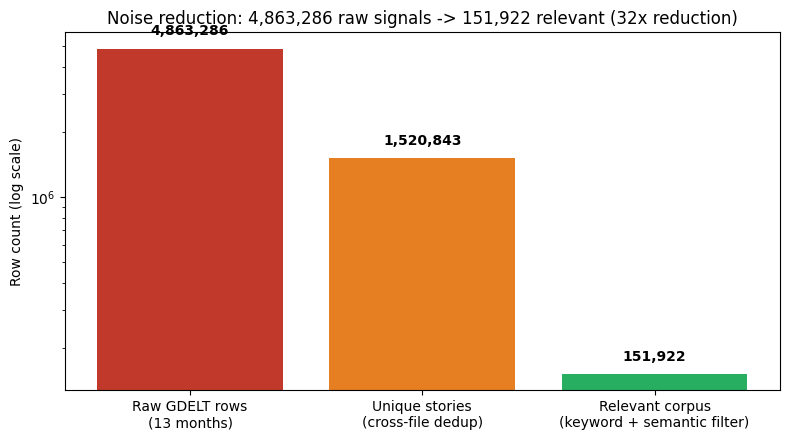


4,863,286 raw signals across GDELT/vessel/fundamentals/sanctions feeds
reduced to 151,922 genuinely relevant, corridor-tagged stories --
a 32x reduction, with full provenance back to
every raw file/row each surviving story came from.


In [18]:
if check_exists(STEP1_CORPUS_JSON, "the Step 1 preprocessing notebook"):
    with open(STEP1_CORPUS_JSON) as f:
        corpus = json.load(f)
    n_relevant = len(corpus)

    funnel_labels = ["Raw GDELT rows\n(13 months)", "Unique stories\n(cross-file dedup)", "Relevant corpus\n(keyword + semantic filter)"]
    funnel_values = [STEP1_RAW_ROW_COUNT, STEP1_UNIQUE_STORY_COUNT, n_relevant]

    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(funnel_labels, funnel_values, color=["#c0392b", "#e67e22", "#27ae60"])
    ax.set_yscale("log")
    ax.set_ylabel("Row count (log scale)")
    ax.set_title(f"Noise reduction: {STEP1_RAW_ROW_COUNT:,} raw signals -> {n_relevant:,} relevant "
                 f"({STEP1_RAW_ROW_COUNT / max(n_relevant,1):.0f}x reduction)")
    for bar, val in zip(bars, funnel_values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.15, f"{val:,}",
                ha="center", fontsize=10, fontweight="bold")
    plt.tight_layout()
    plt.show()

    print(f"\n{STEP1_RAW_ROW_COUNT:,} raw signals across GDELT/vessel/fundamentals/sanctions feeds")
    print(f"reduced to {n_relevant:,} genuinely relevant, corridor-tagged stories --")
    print(f"a {STEP1_RAW_ROW_COUNT / max(n_relevant,1):.0f}x reduction, with full provenance back to")
    print(f"every raw file/row each surviving story came from.")


## 3. Tier 1 — always-on quantitative composite score

Cheap, no LLM calls, runs continuously. Blends news severity, vessel congestion (AIS), and
fundamentals (Brent/Indian basket price deviation) into one auditable per-corridor score.

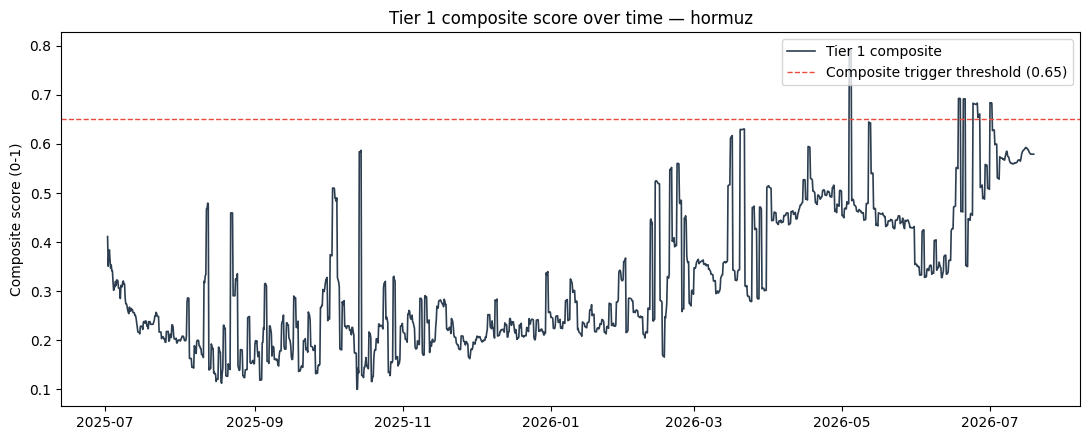

9,174 corridor-timestamps scored across 6 corridors, 2025-07-02 -> 2026-07-19


In [19]:
if check_exists(TIER1_COMPOSITE_PATH, "the Tier 1 quant sub-scores notebook"):
    composite = pd.read_csv(TIER1_COMPOSITE_PATH)
    composite["as_of"] = pd.to_datetime(composite["as_of"], utc=True)

    sub = composite[composite["corridor_id"] == DEMO_CORRIDOR].sort_values("as_of")
    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.plot(sub["as_of"], sub["tier1_composite_score"], color="#2c3e50", linewidth=1.2, label="Tier 1 composite")
    ax.axhline(0.65, color="#e74c3c", linestyle="--", linewidth=1, label="Composite trigger threshold (0.65)")
    ax.set_title(f"Tier 1 composite score over time — {DEMO_CORRIDOR}")
    ax.set_ylabel("Composite score (0-1)")
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

    print(f"{len(composite):,} corridor-timestamps scored across {composite['corridor_id'].nunique()} corridors, "
          f"{composite['as_of'].min().date()} -> {composite['as_of'].max().date()}")


## 4. Step 3 — RAG retrieval in action

A live retrieval call (no LLM, just TF-IDF + cosine similarity — free and fast) against the real
evidence store, showing the credibility-tier-sorted evidence the Hawk/Dove agents actually see.

In [20]:
if all(check_exists(p, "the Step 3 RAG notebooks") for p in [RAG_CHUNKS_PATH, RAG_MATRIX_PATH, RAG_VECTORIZER_PATH]):
    chunks_df = pd.read_csv(RAG_CHUNKS_PATH)
    chunks_df["as_of"] = pd.to_datetime(chunks_df["as_of"], utc=True)
    rag_matrix = sparse.load_npz(RAG_MATRIX_PATH)
    with open(RAG_VECTORIZER_PATH, "rb") as f:
        rag_vectorizer = pickle.load(f)

    from sklearn.metrics.pairwise import cosine_similarity
    CREDIBILITY_ORDER = {"high": 0, "medium": 1, "low": 2}

    def retrieve(corridor_id, as_of, query_text, top_k=8, lookback_days=14):
        as_of = pd.Timestamp(as_of)
        if as_of.tzinfo is None:
            as_of = as_of.tz_localize("UTC")
        window_start = as_of - timedelta(days=lookback_days)
        mask = ((chunks_df["corridor_id"] == corridor_id) & (chunks_df["as_of"] >= window_start) & (chunks_df["as_of"] <= as_of))
        idx = np.flatnonzero(mask.to_numpy())
        if len(idx) == 0:
            return chunks_df.iloc[0:0]
        sub_matrix = rag_matrix[idx]
        sims = cosine_similarity(rag_vectorizer.transform([query_text]), sub_matrix).flatten()
        sub = chunks_df.iloc[idx].copy()
        sub["similarity"] = sims
        sub["_cr"] = sub["credibility_tier"].map(CREDIBILITY_ORDER).fillna(1)
        return sub.sort_values(["_cr", "similarity"], ascending=[True, False]).head(top_k).drop(columns=["_cr"])

    demo_as_of = chunks_df.loc[chunks_df["corridor_id"] == DEMO_CORRIDOR, "as_of"].max()
    demo_query = f"supply disruption risk event {DEMO_CORRIDOR.replace('_',' ')} tanker shipping oil"
    hits = retrieve(DEMO_CORRIDOR, demo_as_of, demo_query)

    print(f"Query: \"{demo_query}\"  |  Corridor: {DEMO_CORRIDOR}  |  As of: {demo_as_of}\n")
    for _, r in hits.iterrows():
        print(f"  [{r['credibility_tier'].upper():>6}] sim={r['similarity']:.3f}  {r['domain']}")
        print(f"           {r['chunk_text'][:140]}...")


Query: "supply disruption risk event hormuz tanker shipping oil"  |  Corridor: hormuz  |  As of: 2026-07-18 16:45:00+00:00

  [  HIGH] sim=0.136  cnbc.com
           iran war oil tanker strait hormuz traffic attacks trump . IRAN OIL TANKER OIL TANKER IRAN OIL TANKER OMAN OMAN OMAN . hormuz iran oil strait...
  [  HIGH] sim=0.115  cnbc.com
           oil price strait hormuz iran trump tanker . NAVAL CIVILIAN . hormuz iran naval oil strait tanker...
  [  HIGH] sim=0.095  gcaptain.com
           intertanko warns threat to shipping now extends across gulf region as hormuz transits continue to fall . MILITARY MERCHANT . gulf hormuz mil...
  [  HIGH] sim=0.089  gcaptain.com
           tanker struck by projectile near hormuz sparking fire . IRAN   IRAN . hormuz iran tanker...
  [  HIGH] sim=0.088  cnbc.com
           oil prices iran strait hormuz . IRAN  . hormuz iran oil strait...
  [  HIGH] sim=0.073  cnbc.com
           us iran hormuz strikes oil toll . THE ASSOCIATED PRESS BAHRAIN . hormu

## 5. The centerpiece — the Hawk vs. Dove debate

This is the actual novelty, and it's shown here as a **debate, not a scoreboard**: two
independent LLM analysts open with opposite conclusions on the *same* evidence, then each sees
the other's opening position and gets one turn to rebut or concede specific cited points,
before a third, separate LLM adjudicates. Showing only the final numbers would hide the thing
that's actually adversarial about this — the fact that Hawk and Dove read the same evidence
and, unprompted by each other, land in different places, then have to engage with each other's
specific citations rather than just restating themselves.

The episode shown below is picked automatically: **highest disagreement_index**, since that's
the most interesting case to show a judge — it's exactly the scenario the whole dual-agent
design exists for.

EPISODE: bab_el_mandeb  |  as of 2025-12-01 18:00:00+00:00
Tier 1 composite going in: 0.208

[ROUND 1 -- sealed-bid, neither agent sees the other]

  HAWK opens -- score: 0.6
    The news sub-score is lower than the Tier 1 quantitative baseline (0.204 vs 0.208), but recent news events suggest a higher disruption risk. On November 23rd, a tanker was mentioned in Djibouti (gdelt:d68a551e8c1a6bd0:0), which is part of the Bab el Mandeb corridor. Additionally, on November 28th, there was news about Australia's crude oil and a captain from France (gdelt:d948ab54482c973c:0). These events could potentially disrupt the energy supply chain in this region. Furthermore, Yemen has been mentioned multiple times in recent news (gdelt:1374c852e5d1ef41:0, gdelt:9d5af6c68186f434:0, gdelt:1af4dcaad6cb5f9f:0, gdelt:c48719569649050b:0, gdelt:8ece5b37c5b09e8a:0, gdelt:b40d473e3d6b4e03:0), which is a conflict-prone country that could impact the corridor's stability.
    cited: ['gdelt:d68a551e8c1a6bd0:0', 'g

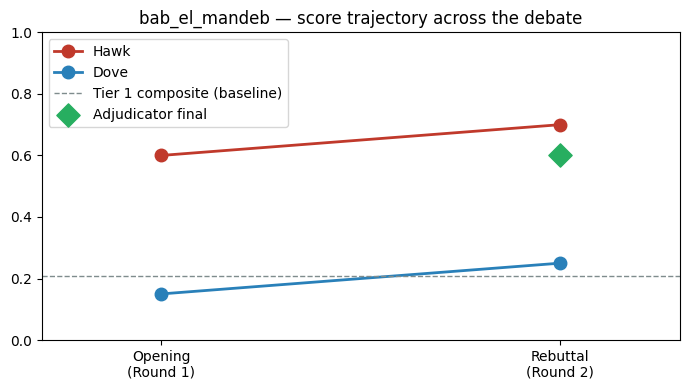

In [21]:
if check_exists(STEP4_FINAL_RESULTS_PATH, "Step 4 Part 1 + Part 2 (with RUN_LIVE_CALLS=True)") \
        and check_exists(STEP4_ROUND1_PATH, "Step 4 Part 1"):
    with open(STEP4_FINAL_RESULTS_PATH) as f:
        final_results = json.load(f)
    with open(STEP4_ROUND1_PATH) as f:
        round1_results = json.load(f)

    scored = {k: v for k, v in final_results.items() if v["adjudicator"].get("disagreement_index") is not None}
    if not scored:
        print("No fully-scored episodes found (all dry-run or null). Run Step 4 with RUN_LIVE_CALLS=True first.")
    else:
        demo_key = max(scored, key=lambda k: scored[k]["adjudicator"]["disagreement_index"])
        r = scored[demo_key]
        r1 = round1_results.get(demo_key, {})
        hawk_r1, dove_r1 = r1.get("hawk", {}), r1.get("dove", {})

        print("=" * 78)
        print(f"EPISODE: {r['corridor_id']}  |  as of {r['as_of']}")
        print(f"Tier 1 composite going in: {r['tier1_composite_score']:.3f}")
        print("=" * 78)

        print("\n[ROUND 1 -- sealed-bid, neither agent sees the other]")
        print(f"\n  HAWK opens -- score: {hawk_r1.get('score')}")
        print(f"    {hawk_r1.get('argument')}")
        print(f"    cited: {hawk_r1.get('cited_evidence_ids')}")
        print(f"\n  DOVE opens -- score: {dove_r1.get('score')}")
        print(f"    {dove_r1.get('argument')}")
        print(f"    cited: {dove_r1.get('cited_evidence_ids')}")

        if hawk_r1.get("score") is not None and dove_r1.get("score") is not None:
            print(f"\n  Opening disagreement: {abs(hawk_r1['score'] - dove_r1['score']):.3f}")

        print("\n[ROUND 2 -- each agent has now seen the other's opening, one turn to rebut/concede]")
        print(f"\n  HAWK rebuts -- score: {r['hawk']['score']}")
        print(f"    {r['hawk']['argument']}")
        print(f"    cited: {r['hawk']['cited_evidence_ids']}")
        print(f"\n  DOVE rebuts -- score: {r['dove']['score']}")
        print(f"    {r['dove']['argument']}")
        print(f"    cited: {r['dove']['cited_evidence_ids']}")

        adj = r["adjudicator"]
        print(f"\n[ADJUDICATOR -- sees the full 4-message transcript above, not just the two final scores]")
        print(f"\n  Final score: {adj['final_score']}   Confidence band: {adj['confidence_band']}")
        print(f"  Disagreement index (post-rebuttal): {adj['disagreement_index']:.3f}"
              + ("   >>> FLAGGED FOR HUMAN REVIEW" if adj["human_review_flag"] else ""))
        if adj.get("credibility_floor_applied"):
            print(f"  >>> Credibility floor applied: Dove's score was overridden upward because")
            print(f"      Hawk cited high-credibility evidence -- the guardrail firing for real.")
        print(f"  Rationale: {adj['rationale']}")

        # Score trajectory: shows each agent moving (or not) after seeing the other's argument --
        # this is the visual proof of adversarial engagement, not just two static opinions.
        fig, ax = plt.subplots(figsize=(7, 4))
        stages = ["Opening\n(Round 1)", "Rebuttal\n(Round 2)"]
        if hawk_r1.get("score") is not None and r["hawk"]["score"] is not None:
            ax.plot(stages, [hawk_r1["score"], r["hawk"]["score"]], "o-", color="#c0392b",
                    linewidth=2, markersize=9, label="Hawk")
        if dove_r1.get("score") is not None and r["dove"]["score"] is not None:
            ax.plot(stages, [dove_r1["score"], r["dove"]["score"]], "o-", color="#2980b9",
                    linewidth=2, markersize=9, label="Dove")
        ax.axhline(r["tier1_composite_score"], color="#7f8c8d", linestyle="--", linewidth=1,
                   label="Tier 1 composite (baseline)")
        ax.scatter([1], [adj["final_score"]], color="#27ae60", s=140, zorder=5,
                   label="Adjudicator final", marker="D")
        ax.set_ylim(0, 1)
        ax.set_xlim(-0.3, 1.3)
        ax.set_title(f"{r['corridor_id']} — score trajectory across the debate")
        ax.legend(loc="best")
        plt.tight_layout()
        plt.show()


## 5b. Debate quality metrics — does the adversarial process actually do anything?

One episode is a story; these numbers are the evidence that the debate structure isn't
decorative. Computed across **every** fully-scored episode, not the cherry-picked one above:

- **Do the agents actually move?** If Round 2 scores always equal Round 1, "rebuttal" is a
  no-op and this is a single model talking to itself twice. Mean |R2 - R1| per agent shows
  whether seeing the other side's citations changes anything.
- **Citation hallucination rate** — how often either agent cited an `evidence_id` that wasn't in
  its own retrieved bundle (caught and stripped by `parse_debate_json`, not silently allowed).
- **Human-review flag rate** and **credibility-floor trigger rate** — how often the guardrails
  actually fire, not just whether they exist in the code.

Episodes fully scored: 50

Mean Hawk score movement after seeing Dove's opening: 0.132
Mean Dove score movement after seeing Hawk's opening: 0.143
Mean disagreement -- opening (Round 1):  0.208
Mean disagreement -- post-rebuttal:       0.093
  -> rebuttal narrowed average disagreement by 0.115

Citation hallucination rate (Round 1, both agents): 7/509 (1.4%)
Human-review flag rate: 1/50 (2.0%)
Credibility-floor applied rate: 0/50 (0.0%)


C:\Users\ejisg\AppData\Local\Temp\ipykernel_9400\1658884989.py:64: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([hawk_moves, dove_moves], labels=["Hawk", "Dove"])


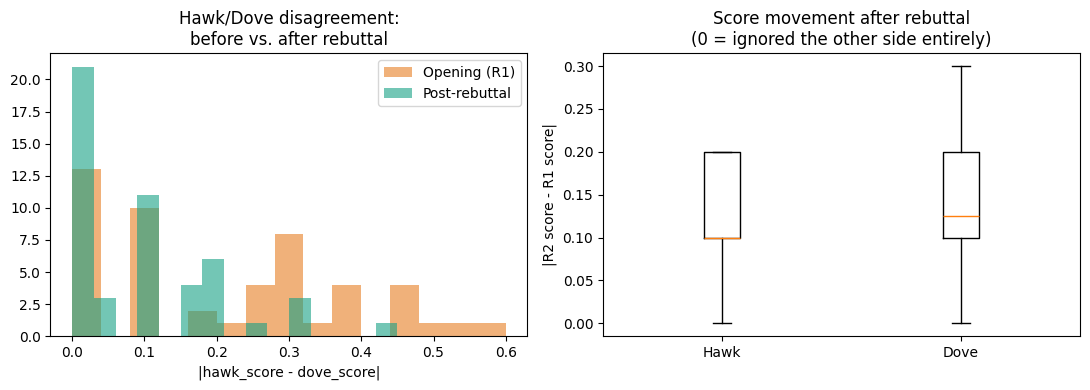

In [22]:
if check_exists(STEP4_FINAL_RESULTS_PATH, "Step 4") and check_exists(STEP4_ROUND1_PATH, "Step 4 Part 1"):
    with open(STEP4_FINAL_RESULTS_PATH) as f:
        final_results = json.load(f)
    with open(STEP4_ROUND1_PATH) as f:
        round1_results = json.load(f)

    scored_keys = [k for k, v in final_results.items() if v["adjudicator"].get("disagreement_index") is not None]
    n_scored = len(scored_keys)

    if n_scored == 0:
        print("No fully-scored episodes yet -- run Step 4 with RUN_LIVE_CALLS=True first.")
    else:
        hawk_moves, dove_moves = [], []
        opening_disagreements, rebuttal_disagreements = [], []
        n_cited_total, n_hallucinated_total = 0, 0

        for k in scored_keys:
            r = final_results[k]
            r1 = round1_results.get(k, {})
            hawk_r1, dove_r1 = r1.get("hawk", {}), r1.get("dove", {})

            if hawk_r1.get("score") is not None and r["hawk"]["score"] is not None:
                hawk_moves.append(abs(r["hawk"]["score"] - hawk_r1["score"]))
            if dove_r1.get("score") is not None and r["dove"]["score"] is not None:
                dove_moves.append(abs(r["dove"]["score"] - dove_r1["score"]))
            if hawk_r1.get("score") is not None and dove_r1.get("score") is not None:
                opening_disagreements.append(abs(hawk_r1["score"] - dove_r1["score"]))
            if r["hawk"]["score"] is not None and r["dove"]["score"] is not None:
                rebuttal_disagreements.append(abs(r["hawk"]["score"] - r["dove"]["score"]))

            for role_r1 in (hawk_r1, dove_r1):
                n_cited_total += len(role_r1.get("cited_evidence_ids", [])) + role_r1.get("n_hallucinated_citations", 0)
                n_hallucinated_total += role_r1.get("n_hallucinated_citations", 0)

        n_human_review = sum(1 for k in scored_keys if final_results[k]["adjudicator"]["human_review_flag"])
        n_floor_applied = sum(1 for k in scored_keys if final_results[k]["adjudicator"].get("credibility_floor_applied"))

        print(f"Episodes fully scored: {n_scored}")
        print()
        print(f"Mean Hawk score movement after seeing Dove's opening: {np.mean(hawk_moves):.3f}"
              if hawk_moves else "Mean Hawk score movement: n/a")
        print(f"Mean Dove score movement after seeing Hawk's opening: {np.mean(dove_moves):.3f}"
              if dove_moves else "Mean Dove score movement: n/a")
        if opening_disagreements and rebuttal_disagreements:
            print(f"Mean disagreement -- opening (Round 1):  {np.mean(opening_disagreements):.3f}")
            print(f"Mean disagreement -- post-rebuttal:       {np.mean(rebuttal_disagreements):.3f}")
            delta = np.mean(opening_disagreements) - np.mean(rebuttal_disagreements)
            print(f"  -> rebuttal {'narrowed' if delta > 0 else 'widened'} average disagreement by {abs(delta):.3f}")
        print()
        print(f"Citation hallucination rate (Round 1, both agents): "
              f"{n_hallucinated_total}/{n_cited_total} "
              f"({n_hallucinated_total / n_cited_total:.1%})" if n_cited_total else "no citations recorded")
        print(f"Human-review flag rate: {n_human_review}/{n_scored} ({n_human_review / n_scored:.1%})")
        print(f"Credibility-floor applied rate: {n_floor_applied}/{n_scored} ({n_floor_applied / n_scored:.1%})")

        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        if opening_disagreements and rebuttal_disagreements:
            axes[0].hist(opening_disagreements, bins=15, alpha=0.6, label="Opening (R1)", color="#e67e22")
            axes[0].hist(rebuttal_disagreements, bins=15, alpha=0.6, label="Post-rebuttal", color="#16a085")
            axes[0].set_title("Hawk/Dove disagreement:\nbefore vs. after rebuttal")
            axes[0].set_xlabel("|hawk_score - dove_score|")
            axes[0].legend()
        if hawk_moves or dove_moves:
            axes[1].boxplot([hawk_moves, dove_moves], labels=["Hawk", "Dove"])
            axes[1].set_title("Score movement after rebuttal\n(0 = ignored the other side entirely)")
            axes[1].set_ylabel("|R2 score - R1 score|")
        plt.tight_layout()
        plt.show()


## 6. Guardrail proof — live injection-resistance check

Not a claim, a live test: a fabricated "Strait of Hormuz fully closed" story from a
known-low-credibility domain is injected into a *copy* of the real evidence store, and we
confirm the credibility-tier-sort keeps it out of the evidence the agents actually see. Free
and fast — no LLM call.

In [23]:
if all(check_exists(p, "Step 3") for p in [RAG_CHUNKS_PATH, RAG_MATRIX_PATH, RAG_VECTORIZER_PATH]):
    fake_text = "BREAKING strait of hormuz fully closed all tanker traffic halted immediately"
    fake_row = {
        "chunk_id": "INJECTED_TEST:0", "story_id": "INJECTED_TEST", "chunk_index": 0,
        "chunk_text": fake_text, "corridor_id": DEMO_CORRIDOR, "domain": "quicknews-africa.net",
        "credibility_tier": "low", "canonical_url": "//quicknews-africa.net/fake",
        "as_of": demo_as_of, "relevance_reason": "injected_test", "mention_count": 1,
    }
    test_chunks_df = pd.concat([chunks_df, pd.DataFrame([fake_row])], ignore_index=True)
    fake_vec = rag_vectorizer.transform([fake_text])
    test_matrix = sparse.vstack([rag_matrix, fake_vec])

    def retrieve_test(df, matrix, corridor_id, as_of, query_text, top_k=8, lookback_days=14):
        as_of = pd.Timestamp(as_of)
        window_start = as_of - timedelta(days=lookback_days)
        mask = ((df["corridor_id"] == corridor_id) & (df["as_of"] >= window_start) & (df["as_of"] <= as_of))
        idx = np.flatnonzero(mask.to_numpy())
        sub_matrix = matrix[idx]
        sims = cosine_similarity(rag_vectorizer.transform([query_text]), sub_matrix).flatten()
        sub = df.iloc[idx].copy()
        sub["similarity"] = sims
        sub["_cr"] = sub["credibility_tier"].map(CREDIBILITY_ORDER).fillna(1)
        return sub.sort_values(["_cr", "similarity"], ascending=[True, False]).head(top_k).drop(columns=["_cr"])

    hits = retrieve_test(test_chunks_df, test_matrix, DEMO_CORRIDOR, demo_as_of,
                          "strait of hormuz closed shipping halted tanker traffic suspended")
    print(hits[["chunk_id", "domain", "credibility_tier", "similarity"]].to_string(index=False))

    injected_pos = hits.reset_index(drop=True)
    injected_pos = injected_pos.index[injected_pos["chunk_id"] == "INJECTED_TEST:0"]
    if len(injected_pos) == 0:
        print("\nPASS -- fabricated low-credibility story did not make the top-8 evidence at all.")
    else:
        print(f"\nCHECK -- fabricated story appeared at position {injected_pos[0]}, review before trusting.")


          chunk_id        domain credibility_tier  similarity
ded4c0ee90732fbf:0  gcaptain.com             high    0.199106
d2449452d2ebc2a5:0      cnbc.com             high    0.186917
13c9b3c2d8adc19c:0      cnbc.com             high    0.165216
053fb9cb7295b005:0      cnbc.com             high    0.151164
fe051b6f8a9b2430:0  gcaptain.com             high    0.103962
6cf14a7a9fa4806e:0  gcaptain.com             high    0.097839
06a8187d85f45b63:0  gcaptain.com             high    0.094750
471f9844433820cb:0 aljazeera.com             high    0.083511

PASS -- fabricated low-credibility story did not make the top-8 evidence at all.


## 7. Scalability — how much of the pipeline actually needs the expensive LLM debate

The whole point of the two-tier design: Tier 1 (free, continuous) screens everything; Tier 2
(the LLM debate) only fires on the ambiguous minority. Three stages, not two — total
corridor-timestamps, how many actually cross the trigger condition, and how many *episodes*
that collapses into (adjacent triggered points merge into one episode, so this is the real
number of times the expensive debate runs).

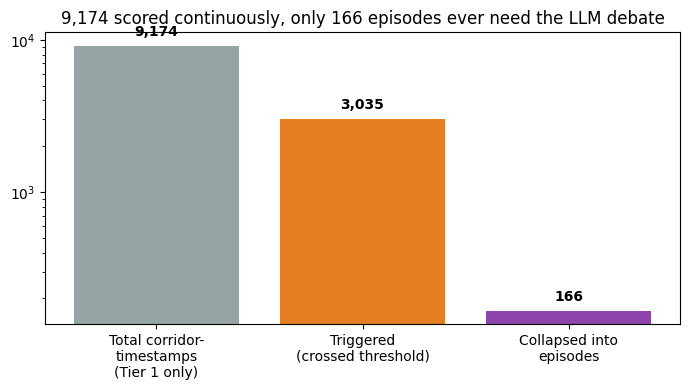

Trigger rate: 33.1% of all corridor-timestamps
Collapse ratio: 18.3x (triggered points -> episodes)
Tier 2 (the expensive path) processes 1.81% of what Tier 1 screens continuously -- this is the scalability story for the judges.
LLM call budget: 166 episodes x 5 calls (Hawk R1, Dove R1, Hawk R2, Dove R2, Adjudicator) = 830 total calls for full corpus coverage.


In [24]:
if check_exists(TIER1_COMPOSITE_PATH, "Tier 1") and check_exists(STEP4_EPISODES_PATH, "Step 4"):
    episodes = pd.read_csv(STEP4_EPISODES_PATH)
    n_total_gridpoints = len(composite)
    n_episodes = len(episodes)

    # Recompute the trigger flag the same way Step 4/5 do, using the calibrated thresholds if
    # available, so this bar is a real count rather than a stand-in.
    composite_threshold, disagreement_threshold = 0.65, 0.35
    if check_exists(CALIBRATED_CONFIG_PATH, "Step 5 calibration"):
        with open(CALIBRATED_CONFIG_PATH) as f:
            cal = json.load(f)
        composite_threshold = cal.get("composite_trigger_threshold", composite_threshold)
        disagreement_threshold = cal.get("subscore_disagreement_threshold", disagreement_threshold)

    sub_cols = [c for c in ["news_subscore", "vessel_subscore", "fundamentals_subscore"] if c in composite.columns]

    def _spread(row):
        vals = [row[c] for c in sub_cols if pd.notna(row[c])]
        return (max(vals) - min(vals)) if len(vals) > 1 else 0.0

    spread = composite.apply(_spread, axis=1)
    triggered_mask = (composite["tier1_composite_score"] >= composite_threshold) | (spread >= disagreement_threshold)
    n_triggered_gridpoints = int(triggered_mask.sum())

    fig, ax = plt.subplots(figsize=(7, 4))
    labels = ["Total corridor-\ntimestamps\n(Tier 1 only)", "Triggered\n(crossed threshold)", "Collapsed into\nepisodes"]
    values = [n_total_gridpoints, n_triggered_gridpoints, n_episodes]
    ax.bar(labels, values, color=["#95a5a6", "#e67e22", "#8e44ad"])
    ax.set_yscale("log")
    for i, v in enumerate(values):
        ax.text(i, v * 1.15, f"{v:,}", ha="center", fontweight="bold")
    ax.set_title(f"{n_total_gridpoints:,} scored continuously, only {n_episodes:,} episodes ever need the LLM debate")
    plt.tight_layout()
    plt.show()

    print(f"Trigger rate: {n_triggered_gridpoints / max(n_total_gridpoints,1):.1%} of all corridor-timestamps")
    print(f"Collapse ratio: {n_triggered_gridpoints / max(n_episodes,1):.1f}x (triggered points -> episodes)")
    print(f"Tier 2 (the expensive path) processes {n_episodes / max(n_total_gridpoints,1):.2%} "
          f"of what Tier 1 screens continuously -- this is the scalability story for the judges.")
    print(f"LLM call budget: {n_episodes:,} episodes x 5 calls (Hawk R1, Dove R1, Hawk R2, Dove R2, "
          f"Adjudicator) = {n_episodes * 5:,} total calls for full corpus coverage.")


## 8. Final output — ranked Disruption Alerts

The actual deliverable a procurement or policy desk would read every morning.

In [25]:
if check_exists(DISRUPTION_ALERTS_PATH, "Step 5-apply / Step 7 (unified feed + alerts export)"):
    alerts = pd.read_csv(DISRUPTION_ALERTS_PATH)
    alerts["as_of"] = pd.to_datetime(alerts["as_of"], utc=True)
    print(f"{len(alerts):,} active disruption alerts\n")
    for _, r in alerts.sort_values("as_of", ascending=False).head(10).iterrows():
        flags = []
        if r.get("human_review_flag"):
            flags.append("HUMAN REVIEW")
        if r.get("credibility_floor_applied"):
            flags.append("credibility floor applied")
        flag_str = f"  [{', '.join(flags)}]" if flags else ""
        print(f"  [{r['corridor_id']:>13}] {r['as_of'].date()}  score={r['effective_score']:.2f}  "
              f"source={r['score_source']}{flag_str}")
elif check_exists(UNIFIED_FEED_PATH, "Step 5-apply / Step 7"):
    print("disruption_alerts.csv not found, but unified_risk_feed.csv is -- showing top scores from that instead:")
    unified = pd.read_csv(UNIFIED_FEED_PATH)
    print(unified.sort_values("effective_score", ascending=False).head(10)[
        ["corridor_id", "as_of", "effective_score", "score_source"]
    ].to_string(index=False))


85 active disruption alerts

  [      red_sea] 2026-07-09  score=0.60  source=tier1_composite_only  [HUMAN REVIEW, credibility floor applied]
  [      red_sea] 2026-07-09  score=0.61  source=tier1_composite_only  [HUMAN REVIEW, credibility floor applied]
  [      red_sea] 2026-07-08  score=0.60  source=tier1_composite_only  [HUMAN REVIEW, credibility floor applied]
  [      red_sea] 2026-07-08  score=0.61  source=tier1_composite_only  [HUMAN REVIEW, credibility floor applied]
  [      red_sea] 2026-07-08  score=0.62  source=tier1_composite_only  [HUMAN REVIEW, credibility floor applied]
  [      red_sea] 2026-07-08  score=0.63  source=tier1_composite_only  [HUMAN REVIEW, credibility floor applied]
  [      red_sea] 2026-07-07  score=0.63  source=tier1_composite_only  [HUMAN REVIEW, credibility floor applied]
  [      red_sea] 2026-07-07  score=0.64  source=tier1_composite_only  [HUMAN REVIEW, credibility floor applied]
  [      red_sea] 2026-07-07  score=0.64  source=tier1_composite_on

## 9. LLM-generated current-affairs briefing

Pulls together everything shown above — the latest Tier 1 score per corridor, the top retrieved
evidence, and the **full Hawk/Dove/Adjudicator debate**, not just the final verdict — into one
written situation report. The briefing is explicitly instructed to narrate the adversarial
path (opening disagreement → what each side conceded or held on rebuttal → how the Adjudicator
resolved it), the same structure shown in Section 5, so it reads like an analyst's note about a
debate rather than a single flat score. The full conversation is also printed in plain text
below, before the LLM call, so you can see exactly what it saw.

In [26]:
import ollama

ENABLE_LLM_BRIEFING = True
OLLAMA_MODEL = "mistral"

BRIEFING_SYSTEM = """You are a geopolitical risk analyst writing a short daily situation \
briefing on energy supply chain corridors for a procurement/policy audience. You will be given \
the latest quantitative risk scores per corridor, retrieved evidence headlines, and (if \
available) the full Hawk/Dove/Adjudicator debate transcript for the most contested corridor.

Rules:
- Base the briefing STRICTLY on the data provided below. Do not invent events, figures, or \
  sources not present in it.
- Write 180-280 words, professional and concise, organized by corridor.
- Where a debate transcript is provided, explicitly walk through the adversarial path: what \
  Hawk argued in the opening, what Dove argued in the opening, whether either side conceded or \
  held its position after seeing the other's rebuttal, and what the Adjudicator ultimately \
  ruled and why. Do not compress this into just "the final score was X" -- the disagreement and \
  how it was resolved is the point.
- End with one sentence naming the single most urgent corridor to watch, based only on the
  scores given.
"""

def build_briefing_context():
    lines = []
    if check_exists(TIER1_COMPOSITE_PATH, "Tier 1"):
        latest = (
            composite.sort_values("as_of")
            .groupby("corridor_id")
            .tail(1)[["corridor_id", "as_of", "tier1_composite_score"]]
        )
        lines.append("Latest Tier 1 composite scores by corridor:")
        for _, r in latest.iterrows():
            lines.append(f"  - {r['corridor_id']}: {r['tier1_composite_score']:.3f} (as of {r['as_of'].date()})")

    if "hits" in dir() and hits is not None and len(hits):
        lines.append(f"\nTop retrieved evidence for {DEMO_CORRIDOR} (as of {demo_as_of}):")
        for _, r in hits.head(4).iterrows():
            lines.append(f"  - [{r['credibility_tier']}] {r['domain']}: {r['chunk_text'][:140]}")

    if check_exists(STEP4_FINAL_RESULTS_PATH, "Step 4") and check_exists(STEP4_ROUND1_PATH, "Step 4 Part 1"):
        with open(STEP4_FINAL_RESULTS_PATH) as f:
            final_results_local = json.load(f)
        with open(STEP4_ROUND1_PATH) as f:
            round1_results_local = json.load(f)
        scored_local = {k: v for k, v in final_results_local.items()
                         if v["adjudicator"].get("disagreement_index") is not None}
        if scored_local:
            demo_key = max(scored_local, key=lambda k: scored_local[k]["adjudicator"]["disagreement_index"])
            r = scored_local[demo_key]
            r1 = round1_results_local.get(demo_key, {})
            hawk_r1, dove_r1 = r1.get("hawk", {}), r1.get("dove", {})
            adj = r["adjudicator"]

            lines.append(f"\nFull Hawk/Dove/Adjudicator debate -- {r['corridor_id']} (as of {r['as_of']}):")
            lines.append(f"  ROUND 1 (opening, sealed-bid, neither agent saw the other):")
            lines.append(f"    Hawk (score {hawk_r1.get('score')}): {hawk_r1.get('argument')}")
            lines.append(f"    Dove (score {dove_r1.get('score')}): {dove_r1.get('argument')}")
            lines.append(f"  ROUND 2 (rebuttal, each saw the other's opening):")
            lines.append(f"    Hawk (score {r['hawk']['score']}): {r['hawk']['argument']}")
            lines.append(f"    Dove (score {r['dove']['score']}): {r['dove']['argument']}")
            lines.append(f"  ADJUDICATOR: final score {adj['final_score']}, "
                         f"confidence band {adj['confidence_band']}, "
                         f"disagreement index {adj['disagreement_index']:.3f}"
                         + (" [FLAGGED FOR HUMAN REVIEW]" if adj["human_review_flag"] else ""))
            lines.append(f"    Rationale: {adj['rationale']}")
            if adj.get("credibility_floor_applied"):
                lines.append(f"    (Credibility floor was applied -- Dove was overridden upward "
                             f"because Hawk cited high-credibility evidence.)")

    return "\n".join(lines) if lines else None

if ENABLE_LLM_BRIEFING:
    context = build_briefing_context()
    if context is None:
        print("No upstream data available yet to brief on -- run the sections above first.")
    else:
        print("--- Context assembled for the briefing (for transparency, this is all it sees) ---")
        print(context)
        print("\n--- Generating briefing ---\n")
        try:
            resp = ollama.chat(
                model=OLLAMA_MODEL,
                messages=[
                    {"role": "system", "content": BRIEFING_SYSTEM},
                    {"role": "user", "content": context},
                ],
                options={"temperature": 0.3},
            )
            print(resp["message"]["content"])
        except Exception as e:
            print(f"[Ollama not reachable: {e}]")
            print("Start Ollama (`ollama serve`) and confirm `mistral` is pulled, then re-run this cell.")
else:
    print("LLM briefing disabled (ENABLE_LLM_BRIEFING=False).")


--- Context assembled for the briefing (for transparency, this is all it sees) ---
Latest Tier 1 composite scores by corridor:
  - suez: 0.418 (as of 2026-07-19)
  - red_sea: 0.567 (as of 2026-07-19)
  - bab_el_mandeb: 0.363 (as of 2026-07-19)
  - hormuz: 0.579 (as of 2026-07-19)
  - persian_gulf: 0.530 (as of 2026-07-19)
  - india: 0.516 (as of 2026-07-19)

Full Hawk/Dove/Adjudicator debate -- bab_el_mandeb (as of 2025-12-01 18:00:00+00:00):
  ROUND 1 (opening, sealed-bid, neither agent saw the other):
    Hawk (score 0.6): The news sub-score is lower than the Tier 1 quantitative baseline (0.204 vs 0.208), but recent news events suggest a higher disruption risk. On November 23rd, a tanker was mentioned in Djibouti (gdelt:d68a551e8c1a6bd0:0), which is part of the Bab el Mandeb corridor. Additionally, on November 28th, there was news about Australia's crude oil and a captain from France (gdelt:d948ab54482c973c:0). These events could potentially disrupt the energy supply chain in this re

In [27]:
CORRIDOR_ALIASES = {
    "hormuz": "hormuz", "strait of hormuz": "hormuz",
    "bab el mandeb": "bab_el_mandeb", "bab-el-mandeb": "bab_el_mandeb", "bab_el_mandeb": "bab_el_mandeb",
    "suez": "suez",
    "red sea": "red_sea", "red_sea": "red_sea",
    "persian gulf": "persian_gulf", "persian_gulf": "persian_gulf", "arabian gulf": "persian_gulf",
    "india": "india", "indian": "india",
}

QA_SYSTEM = """You are answering live questions during a hackathon demo of an energy supply \
chain risk agent. You will be given the corridor's latest quantitative risk scores, retrieved \
evidence, and (if available) the full Hawk/Dove/Adjudicator debate transcript for that corridor.

Rules:
- Answer ONLY from the data provided below. Do not invent facts, sources, or numbers not present.
- Every factual claim must be followed by a citation in the form (source: <domain>) using only
  the domains actually given to you.
- If a debate transcript is provided and the question relates to it (why the score is what it
  is, whether there's disagreement, how confident the system is), walk through the actual
  adversarial path -- Hawk's opening, Dove's opening, what each held or conceded on rebuttal,
  and the Adjudicator's ruling -- rather than only citing the final adjudicated score.
- If the provided data doesn't contain enough to answer confidently, say so plainly rather than
  guessing.
- Keep the answer to 4-8 sentences unless the question genuinely needs more.
"""

def infer_corridor(question):
    q = question.lower()
    for alias, corridor in CORRIDOR_ALIASES.items():
        if alias in q:
            return corridor
    return DEMO_CORRIDOR   # fall back to the corridor already featured in this demo

def build_debate_transcript(corridor_id):
    """Full Round 1 + Round 2 + Adjudicator transcript for the highest-disagreement episode
    in this corridor, if Step 4 has been run with RUN_LIVE_CALLS=True. Returns None if the
    files aren't there yet or no episode exists for this corridor."""
    if not (check_exists(STEP4_FINAL_RESULTS_PATH, "Step 4") and check_exists(STEP4_ROUND1_PATH, "Step 4 Part 1")):
        return None
    with open(STEP4_FINAL_RESULTS_PATH) as f:
        final_results_local = json.load(f)
    with open(STEP4_ROUND1_PATH) as f:
        round1_results_local = json.load(f)
    matching = {k: v for k, v in final_results_local.items()
                if v["corridor_id"] == corridor_id and v["adjudicator"].get("disagreement_index") is not None}
    if not matching:
        return None
    ek = max(matching, key=lambda k: matching[k]["adjudicator"]["disagreement_index"])
    r = matching[ek]
    r1 = round1_results_local.get(ek, {})
    hawk_r1, dove_r1 = r1.get("hawk", {}), r1.get("dove", {})
    adj = r["adjudicator"]
    lines = [
        f"Hawk/Dove/Adjudicator debate for {corridor_id} (as of {r['as_of']}):",
        f"  Round 1 (opening) -- Hawk (score {hawk_r1.get('score')}): {hawk_r1.get('argument')}",
        f"  Round 1 (opening) -- Dove (score {dove_r1.get('score')}): {dove_r1.get('argument')}",
        f"  Round 2 (rebuttal) -- Hawk (score {r['hawk']['score']}): {r['hawk']['argument']}",
        f"  Round 2 (rebuttal) -- Dove (score {r['dove']['score']}): {r['dove']['argument']}",
        f"  Adjudicator -- final score {adj['final_score']}, confidence band {adj['confidence_band']}, "
        f"disagreement index {adj['disagreement_index']:.3f}"
        + (" [FLAGGED FOR HUMAN REVIEW]" if adj["human_review_flag"] else ""),
        f"  Adjudicator rationale: {adj['rationale']}",
    ]
    if adj.get("credibility_floor_applied"):
        lines.append("  (Credibility floor applied -- Dove was overridden upward because Hawk cited "
                     "high-credibility evidence.)")
    return "\n".join(lines)

def answer_question(question, top_k=6, lookback_days=14):
    if not all(check_exists(p, "Step 3") for p in [RAG_CHUNKS_PATH, RAG_MATRIX_PATH, RAG_VECTORIZER_PATH]):
        print("Can't answer yet -- RAG artifacts not loaded. Run Section 4 first.")
        return

    corridor_id = infer_corridor(question)
    as_of_q = chunks_df.loc[chunks_df["corridor_id"] == corridor_id, "as_of"].max()

    q_hits = retrieve(corridor_id, as_of_q, question, top_k=top_k, lookback_days=lookback_days)

    context_lines = [f"Question is about corridor: {corridor_id} (as of {as_of_q})"]

    if check_exists(TIER1_COMPOSITE_PATH, "Tier 1"):
        latest_score = (
            composite[composite["corridor_id"] == corridor_id].sort_values("as_of").tail(1)
        )
        if not latest_score.empty:
            context_lines.append(
                f"Latest Tier 1 composite score: {latest_score['tier1_composite_score'].iloc[0]:.3f} "
                f"(as of {latest_score['as_of'].iloc[0].date()})"
            )

    if len(q_hits):
        context_lines.append("\nRetrieved evidence:")
        for _, r in q_hits.iterrows():
            context_lines.append(f"  - [{r['credibility_tier']}] ({r['domain']}) {r['chunk_text'][:200]}")
    else:
        context_lines.append("\nNo retrieved evidence matched this question/corridor/window.")

    transcript = build_debate_transcript(corridor_id)
    if transcript:
        context_lines.append(f"\n{transcript}")

    context = "\n".join(context_lines)
    print("--- Context assembled (this is all the model sees, including the full debate) ---")
    print(context)
    print("\n--- Answer ---\n")
    try:
        resp = ollama.chat(
            model=OLLAMA_MODEL,
            messages=[
                {"role": "system", "content": QA_SYSTEM},
                {"role": "user", "content": f"Question: {question}\n\n{context}"},
            ],
            options={"temperature": 0.2},
        )
        print(resp["message"]["content"])
    except Exception as e:
        print(f"[Ollama not reachable: {e}]")
        print("Start Ollama (`ollama serve`), confirm `mistral` is pulled, then retry.")

# Example -- try this before going live, so the first question in front of judges isn't the first
# time you've seen how it answers:
answer_question("Why is the Hormuz corridor showing elevated risk right now, and did the analysts agree?")


--- Context assembled (this is all the model sees, including the full debate) ---
Question is about corridor: hormuz (as of 2026-07-18 16:45:00+00:00)
Latest Tier 1 composite score: 0.579 (as of 2026-07-19)

Retrieved evidence:
  - [high] (cnbc.com) oil prices iran strait hormuz . IRAN  . hormuz iran oil strait
  - [high] (aljazeera.com) iran lawmakers present hormuz management bill as us war heats up . THE US IRAN . hormuz iran war
  - [high] (gcaptain.com) trump pledges to escalate attacks until iran relents on hormuz . IRAN  QATAR THE US SAUDI ARABIA THE US . hormuz iran
  - [high] (cnbc.com) us iran hormuz strikes oil toll . THE ASSOCIATED PRESS BAHRAIN . hormuz iran oil
  - [high] (gcaptain.com) tanker struck by projectile near hormuz sparking fire . IRAN   IRAN . hormuz iran tanker
  - [high] (gcaptain.com) u s navy sea drones make combat debut in operations near hormuz . COMPANY  OMAN  . hormuz

Hawk/Dove/Adjudicator debate for hormuz (as of 2025-08-22 18:00:00+00:00):
  Round 1

### Live interactive mode

Run this cell during the actual demo — it'll keep prompting for questions until you type
`exit`. Works in a live Jupyter kernel (not in a non-interactive re-run of the whole notebook,
since `input()` needs a live session).

In [ ]:
while True:
    q = input("Ask a question (or type 'exit'): ").strip()
    if q.lower() in ("exit", "quit", ""):
        break
    answer_question(q)
    print("\n" + "="*78 + "\n")


--- Context assembled (this is all the model sees, including the full debate) ---
Question is about corridor: india (as of 2026-07-18 10:15:00+00:00)
Latest Tier 1 composite score: 0.516 (as of 2026-07-19)

Retrieved evidence:
  - [high] (aljazeera.com) there are risks ex india judge behind damning un report on gaza children . CONGRESS SIKH FOREIGN NATIONAL GENEVA HARYANA GANG HARYANA MUSLIM HIGH COURT GANG HIGH COURT MUSLIM IRAN ISRAEL IRAN UNITED S
  - [high] (aljazeera.com) pakistan searches for boeing cargo plane missing over arabian sea . ISLAMABAD BOEING PAKISTAN BOEING
  - [high] (aljazeera.com) oil for unity what is the us mediation plan in libya . LIBYA PAKISTAN PAKISTAN ACTOR PAKISTAN LIBYA PAKISTAN RAWALPINDI PAKISTAN REUTERS RAWALPINDI PAKISTAN REUTERS PAKISTAN REUTERS PAKISTANI UNITED N
  - [high] (aljazeera.com) us iran escalation threatens oil supply recovery warns iea . THE US  . escalation iran oil
  - [high] (aljazeera.com) trump threatens iran after chants for his de